# Route frequencies Figure 3 C&F

Counts routes with reverse directions combined and plots C1/C2 frequencies. The broken scratch cell accessing df.visits has been omitted.

Run from top to bottom in a fresh kernel. Helpers are imported from `a1_helpers.py`.

In [1]:
# Data handling
import os
import re
import csv
import warnings
import itertools as it

import numpy as np
import pandas as pd
from tqdm import tqdm

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import cm
from matplotlib.colors import Normalize
from matplotlib.patches import FancyArrowPatch

# Networks and statistical tests
import networkx as nx
from scipy.stats import binomtest, chi2_contingency, chisquare
import statsmodels.stats.multitest as stm

# Functions stored in a1_helpers.py
from a1_helpers import (
    get_time_taken_sec,
    extract_strategies,
    get_percentages,
    parse_values,
    directed_to_undirected_with_summed_weights,
    graph_primer,
    create_dic,
    percentage_scaler,
    get_transition_df,
    Euclidean_Dist,
)

# Progress bars for pandas
tqdm.pandas()

# Hide deprecation warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

In [2]:
from pathlib import Path

# Run with the notebook's Analysis folder as the working directory.
assert Path('a1_helpers.py').is_file(), 'Set the working directory to the Analysis folder.'
fig_folder = '../Figure_paper/'
Path(fig_folder).mkdir(parents=True, exist_ok=True)
colors = ['#0033ff', '#ff4ff1']

In [3]:
sequence_df = pd.read_csv('../Combined_data/seq_df_2025.csv', index_col=0)
sequence_df['game'] = sequence_df['experiment'].str[-1]

All trials are pooled within each condition and scale before the 10% cutoff. Reverse routes share an identity. Routes below 10% at a particular scale enter others at that scale. Fixed sequence-to-label mappings prevent labels changing when a category is absent.

In [4]:
# One record per trial: all trials contribute once, not once per visited node.
trial_keys = ['ppid', 'cond', 'scale', 'trial_num']
assert sequence_df.groupby(trial_keys)['visits'].nunique().le(1).all(), 'Conflicting routes within a trial'
for_comp = sequence_df.drop_duplicates(trial_keys).copy()
assert for_comp['visits'].notna().all(), 'Missing trial routes'

# Remove start/end hive and combine a route with its reverse.
# Numeric lexicographic ordering gives a stable identity across scales.
routes = for_comp['visits'].str.split('-').map(lambda x: tuple(map(int, x[1:-1])))
assert routes.map(len).gt(0).all(), 'Empty route'
for_comp['sequence'] = routes.map(lambda x: min(x, x[::-1]))
route_counts = (
    for_comp.groupby(['cond', 'scale', 'sequence'])
    .size().reset_index(name='count')
)
route_counts['percentage'] = (
    100 * route_counts['count']
    / route_counts.groupby(['cond', 'scale'])['count'].transform('sum')
)
assert route_counts['count'].sum() == len(for_comp)

# Fixed identities from the original pooled plots; never label by column order.
route_labels = {
    'C1': {
        (2, 3, 4, 5, 6, 7, 8, 9, 10): 'R1',
        (2, 3, 4, 5, 8, 6, 7, 9, 10): 'R2',
    },
    'C2': {
        (2, 3, 4, 5, 6, 7, 8, 9, 10): 'R1',
        (2, 4, 5, 6, 3, 7, 8, 9, 10): 'R2',
        (2, 4, 3, 5, 6, 7, 8, 9, 10): 'R4',
    },
}
scale_order = ['S1', 'S2', 'S3', 'S4', 'S5']
scale_labels = ['XS', 'S', 'M', 'L', 'XL']

## C1 route frequencies

Routes,R1,R2,others
scale,,,
S1,58.59,17.17,24.24
S2,74.71,10.34,14.94
S3,60.22,16.67,23.12
S4,43.68,14.94,41.38
S5,53.54,0.00,46.46


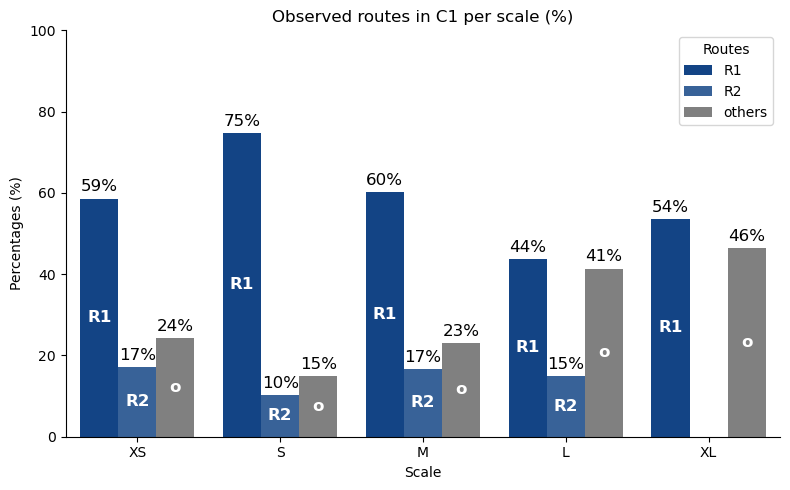

In [5]:
condition = 'C1'
route_order = ['R1', 'R2', 'others']
palette = {'R1': '#004298', 'R2': '#2860a8', 'others': 'grey'}
df = route_counts.loc[route_counts['cond'] == condition].copy()
# Apply 10% to the POOLED frequency within each scale, then group rare routes.
df['Routes'] = df['sequence'].map(route_labels[condition])
unmapped = df.loc[(df['percentage'] >= 10) & df['Routes'].isna(), 'sequence']
assert unmapped.empty, f'Add explicit labels for these routes: {unmapped.tolist()}'
df.loc[df['percentage'] < 10, 'Routes'] = 'others'
pivoted = (
    df.groupby(['scale', 'Routes'])['percentage'].sum().unstack(fill_value=0)
    .reindex(index=scale_order, columns=route_order, fill_value=0)
)
assert np.allclose(pivoted.sum(axis=1), 100), 'Percentages must sum to 100 per scale'
display(pivoted.round(2))
toplot = pivoted.rename_axis(columns='Routes').reset_index().melt(
    id_vars='scale', var_name='Routes', value_name='percentages'
)
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=toplot, x='scale', y='percentages', hue='Routes',
            order=scale_order, hue_order=route_order, palette=palette,
            errorbar=None, ax=ax)
for container, route in zip(ax.containers, route_order):
    values = container.datavalues
    ax.bar_label(container, labels=[f'{v:.0f}%' if v > 0 else '' for v in values], padding=3, fontsize=12)
    ax.bar_label(container, labels=[('o' if route == 'others' else route) if v > 0 else '' for v in values],
                 label_type='center', color='white', weight='bold', fontsize=12)
ax.set(xlabel='Scale', ylabel='Percentages (%)', ylim=(0, 100),
       title=f'Observed routes in {condition} per scale (%)')
ax.set_xticks(range(5), scale_labels)
ax.legend(title='Routes')
sns.despine(ax=ax)
fig.tight_layout()
# Saving remains disabled, as in your notebook.
# fig.savefig(fig_folder + f'Barplot_{condition}.png', dpi=300, bbox_inches='tight')
# fig.savefig(fig_folder + f'Barplot_{condition}.svg', bbox_inches='tight')
plt.show()

## C2 route frequencies

Routes,R1,R2,R4,others
scale,,,,
S1,39.39,29.29,0.0,31.31
S2,54.02,17.24,0.0,28.74
S3,45.70,15.05,0.0,39.25
S4,38.37,10.47,0.0,51.16
S5,20.20,0.00,10.1,69.70


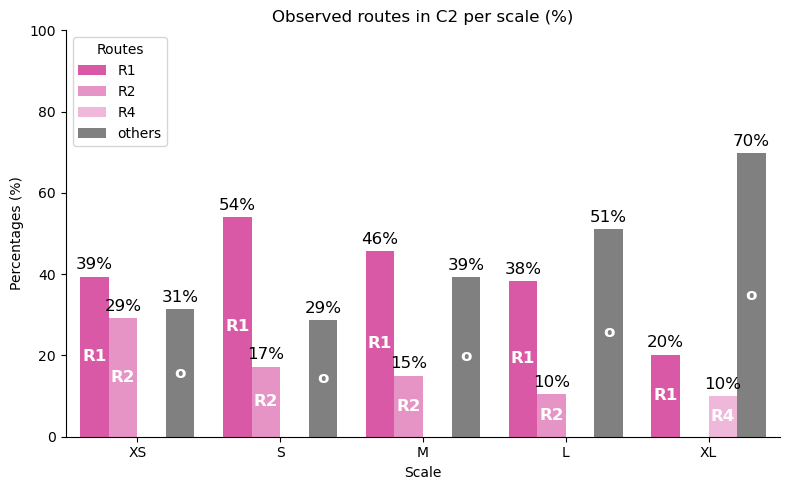

In [6]:
condition = 'C2'
route_order = ['R1', 'R2', 'R4', 'others']
palette = {'R1': '#ee44ab', 'R2': '#f485c8', 'R4': '#f8aedb', 'others': 'grey'}
df = route_counts.loc[route_counts['cond'] == condition].copy()
# Apply 10% to the POOLED frequency within each scale, then group rare routes.
df['Routes'] = df['sequence'].map(route_labels[condition])
unmapped = df.loc[(df['percentage'] >= 10) & df['Routes'].isna(), 'sequence']
assert unmapped.empty, f'Add explicit labels for these routes: {unmapped.tolist()}'
df.loc[df['percentage'] < 10, 'Routes'] = 'others'
pivoted = (
    df.groupby(['scale', 'Routes'])['percentage'].sum().unstack(fill_value=0)
    .reindex(index=scale_order, columns=route_order, fill_value=0)
)
assert np.allclose(pivoted.sum(axis=1), 100), 'Percentages must sum to 100 per scale'
display(pivoted.round(2))
toplot = pivoted.rename_axis(columns='Routes').reset_index().melt(
    id_vars='scale', var_name='Routes', value_name='percentages'
)
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=toplot, x='scale', y='percentages', hue='Routes',
            order=scale_order, hue_order=route_order, palette=palette,
            errorbar=None, ax=ax)
for container, route in zip(ax.containers, route_order):
    values = container.datavalues
    ax.bar_label(container, labels=[f'{v:.0f}%' if v > 0 else '' for v in values], padding=3, fontsize=12)
    ax.bar_label(container, labels=[('o' if route == 'others' else route) if v > 0 else '' for v in values],
                 label_type='center', color='white', weight='bold', fontsize=12)
ax.set(xlabel='Scale', ylabel='Percentages (%)', ylim=(0, 100),
       title=f'Observed routes in {condition} per scale (%)')
ax.set_xticks(range(5), scale_labels)
ax.legend(title='Routes')
sns.despine(ax=ax)
fig.tight_layout()
# Saving remains disabled, as in your notebook.
# fig.savefig(fig_folder + f'Barplot_{condition}.png', dpi=300, bbox_inches='tight')
# fig.savefig(fig_folder + f'Barplot_{condition}.svg', bbox_inches='tight')
plt.show()